c:\Users\paydo\OneDrive\Desktop\asteroid_watch
(500, 256)


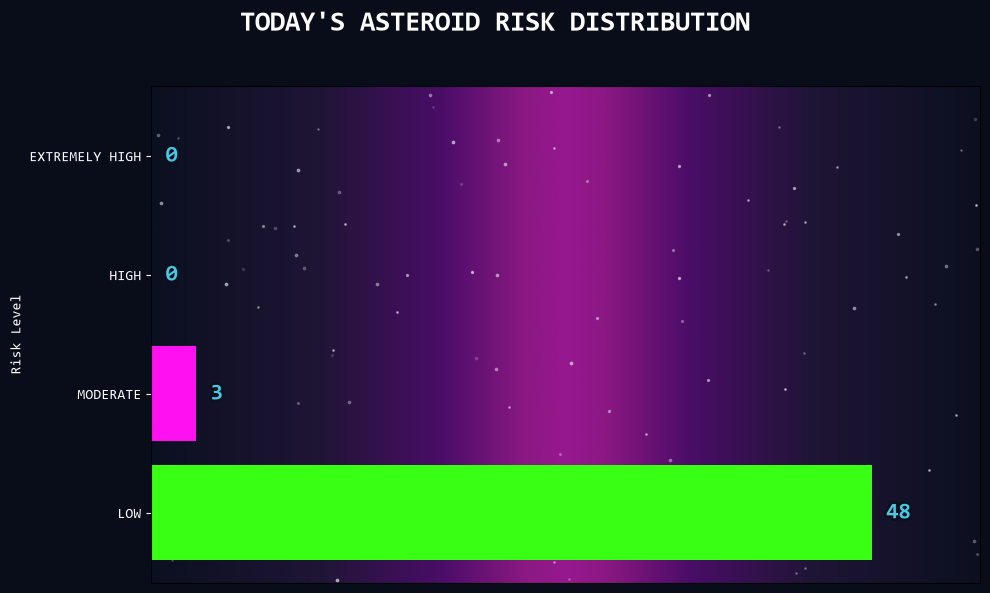

In [67]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patheffects as pe 

from deployment.src.analytics.risk_analytics import RiskAnalytics

# allows for imports from the other files
import sys
from pathlib import Path

project_root = Path.cwd().parents[2]
sys.path.append(str(project_root))
print(project_root)

plt.rcParams["font.family"] = "Consolas"

# query data 
analytics = RiskAnalytics()
results = analytics.get_risk_breakdown()

risk_counts = {
    "LOW": 0,
    "MODERATE": 0,
    "HIGH": 0,
    "EXTREMELY HIGH": 0
}

for row in results:
    risk_counts[row.risk_level.upper()] = row.asteroid_count

risk_levels = np.array(list(risk_counts.keys()))
counts = np.array(list(risk_counts.values()))

colors = np.array([
    "#39FF14", # electric green
    "#FF10F0", # electric pink
    "#FFFF33", # electric yellow
    "#48CAE4", # electric blue
])

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.barh(risk_levels, counts, color=colors)

# numbers at end of bars
for bar in bars:
    width = bar.get_width()
    max_count = counts.max()
    label_offset = max_count * 0.02

    ax.set_xlim(0, max_count * 1.15)

    ax.text(
        width + label_offset,
        bar.get_y() + bar.get_height() / 2,
        str(int(width)),
        color="#48CAE4",
        fontsize=16,
        fontweight="bold",
        va="center",
        path_effects=[
            pe.withStroke(
                linewidth=4,
                foreground="#0B1020"
            )
        ]
    )

fig.patch.set_facecolor("#090D1A")
# ax.set_facecolor("#0B1020")

# gradiant background 
# (im sure there is a better way to do this but i was having fun w this sue me)
space_cmap = LinearSegmentedColormap.from_list(
    "space",
    [
        (0.00, "#0B1020"),
        (0.20, "#1F1535"),
        (0.35, "#4A0D67"),
        (0.45, "#8A1883"),
        (0.50, "#97188F"),
        (0.55, "#8A1883"),
        (0.65, "#4A0D67"),
        (0.80, "#1F1535"),
        (1.00, "#0B1020")
    ]
)

gradient = np.tile(
    np.linspace(0, 1, 256),
    (500, 1)
)

ax.imshow(
    gradient,
    aspect="auto",
    cmap=space_cmap,
    extent=[0, 1, 0, 1],
    transform=ax.transAxes,
    alpha=1.00,
    zorder=0
)

# for x-axis if you want that instead of #'s at end of bar
""" for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(colors="white") """

ax.tick_params(axis="y", colors="white")

# centers the title across the whole image not just plot area
fig.suptitle(
    "TODAY'S ASTEROID RISK DISTRIBUTION",
    color="white",
    fontsize=20,
    fontweight="bold"
)

# ax.set_title("Asteroids by Risk Level", color="white")
# ax.set_xlabel("Number of Asteroids", color="white")

ax.set_xlabel("")
ax.set_xticks([])
ax.set_ylabel("Risk Level", color="white")

# stars
for _ in range(100):
    ax.scatter(
        np.random.rand(),
        np.random.rand(),
        s=np.random.randint(1, 4),
        color="#E9ECEF",
        alpha=np.random.uniform(0.1, 0.6),
        transform=ax.transAxes,
        zorder=0
    )


print(gradient.shape)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("dashboard.png", facecolor=fig.get_facecolor(), transparent=False)
plt.show()